<a href="https://colab.research.google.com/github/DannyJung23/ShoreGate/blob/main/notebooks/RF_Training_and__Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random Forest Training and Validation

## Overview

This notebook develops and evaluates a Random Forest (RF) classifier for pixel-level building damage classification using pre- and post-disaster Sentinel-1 (S1) and Sentinel-2 (S2) satellite data.

The model is trained using labelled data from the 2018 Palu tsunami event. Building damage labels derived from xBD annotations are associated with satellite pixels to create a binary classification dataset.

The objective is to investigate whether changes in multi-sensor satellite features can distinguish intact from damaged building pixels.

## Workflow

1. Loading and inspecting the prepared Palu dataset.
2. Splitting the data by image patch to prevent spatial data leakage.
3. Training and validating a Random Forest classifier.
4. Evaluating classification performance and feature importance.
5. Training a final model on all available Palu samples and saving it for subsequent testing.

## Dataset

The prepared dataset contains 196 Palu patches and 515,989 labelled pixels. Each pixel is represented by 24 features derived from Sentinel-1 and Sentinel-2 pre- and post-disaster observations, including feature changes.

The binary target labels are:

- **0 — Intact:** Pixels predominantly covered by xBD no-damage building annotations.
- **1 — Damaged:** Pixels predominantly covered by xBD minor-, major-, or destroyed-building annotations.

Unclassified, ambiguous, and invalid pixels are excluded from the labelled dataset.

The labelled data are imbalanced, with approximately 6.46 intact pixels for every damaged pixel.

In [1]:
%pip install -q numpy pandas scikit-learn matplotlib seaborn joblib

In [2]:
from pathlib import Path
import requests
import numpy as np
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "DannyJung23/ShoreGate/main/datasets/palu_rf_dataset.npz"
)

DATA_DIR = Path("/content/shoregate_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "palu_rf_dataset.npz"

response = requests.get(DATA_URL, timeout=120)
response.raise_for_status()

DATA_PATH.write_bytes(response.content)

print(f"Dataset downloaded: {DATA_PATH}")
print(f"File size: {DATA_PATH.stat().st_size / (1024**2):.2f} MiB")

Dataset downloaded: /content/shoregate_data/palu_rf_dataset.npz
File size: 32.21 MiB


In [3]:
with np.load(DATA_PATH, allow_pickle=False) as data:
    X = data["X"].astype(np.float32)
    y = data["y"].astype(np.uint8)
    patch_ids = data["patch_ids"].astype(str)
    feature_names = data["feature_names"].astype(str)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique patches:", len(np.unique(patch_ids)))
print("Feature count:", len(feature_names))
print("Labels:", np.unique(y))

assert X.ndim == 2 and X.shape[1] == 24
assert len(X) == len(y) == len(patch_ids)
assert len(feature_names) == X.shape[1]
assert np.isin(y, [0, 1]).all()
assert np.isfinite(X).all()
assert len(np.unique(y)) == 2

print("\nDataset integrity checks passed.")

X shape: (522380, 24)
y shape: (522380,)
Unique patches: 193
Feature count: 24
Labels: [0 1]

Dataset integrity checks passed.


## 1. Dataset Inspection

The dataset contains two classes: intact (0) and damaged (1). Their distribution is imbalanced, so overall accuracy alone will not be sufficient to assess model performance.

Class proportions and the number of samples contributed by each patch are inspected before training.

Intact (0)     452507
Damaged (1)     69873
Name: count, dtype: int64

Class proportions:
Intact (0)     86.62%
Damaged (1)    13.38%
Name: count, dtype: object


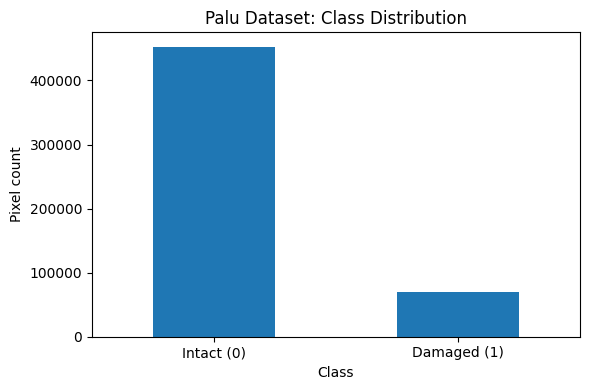

In [4]:
import matplotlib.pyplot as plt

class_counts = pd.Series(y).value_counts().sort_index()
class_counts.index = ["Intact (0)", "Damaged (1)"]

print(class_counts)
print("\nClass proportions:")
print((class_counts / len(y) * 100).round(2).astype(str) + "%")

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Palu Dataset: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Pixel count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. Patch-Level Train–Validation Split

A random pixel-level split would allow pixels from the same image patch to appear in both training and validation sets. This can inflate validation performance because nearby pixels share spatial and environmental characteristics.

Instead, `GroupShuffleSplit` separates complete patches. Approximately 80% of the patches are assigned to training and 20% to validation. The validation set remains separate from model fitting and is used to estimate within-event performance on unseen Palu patches.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=patch_ids)
)

X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

train_patches = np.unique(patch_ids[train_idx])
val_patches = np.unique(patch_ids[val_idx])

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Training patches:", len(train_patches))
print("Validation patches:", len(val_patches))
print("Training class distribution:", np.bincount(y_train, minlength=2))
print("Validation class distribution:", np.bincount(y_val, minlength=2))

assert set(train_patches).isdisjoint(set(val_patches))

assert len(np.unique(y_train)) == 2
assert len(np.unique(y_val)) == 2

print("\nPatch separation verified.")

Training samples: 416483
Validation samples: 105897
Training patches: 154
Validation patches: 39
Training class distribution: [358330  58153]
Validation class distribution: [94177 11720]

Patch separation verified.


## 3. Random Forest Training

A Random Forest classifier is trained using the 24 Sentinel-1/Sentinel-2 features. The model includes pre-event and post-event observations and their differences.

Class weighting is used to reduce the influence of the majority class. The model is fitted exclusively on the training patches; the validation patches are reserved for performance evaluation.

The final model configuration was selected following preliminary experiments with class weighting, classification thresholds, and tree complexity.

The Random Forest uses 300 trees, square-root feature sampling, a minimum leaf size of one, and increased weighting for the damaged class. The classification threshold is set to 0.35 to improve the balance between damaged-class precision and recall.

Training and validation patches remain separated throughout model fitting and evaluation.

In [11]:
from sklearn.ensemble import RandomForestClassifier
import time

THRESHOLD = 0.35

FINAL_PARAMS = {
    "n_estimators": 300,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
    "class_weight": {0: 1, 1: 3},
    "random_state": 42,
    "n_jobs": -1
}

rf_validation = RandomForestClassifier(**FINAL_PARAMS)

print("Training final-configured validation model...")

start_time = time.time()
rf_validation.fit(X_train, y_train)
validation_training_minutes = (time.time() - start_time) / 60

print(
    f"Training completed in "
    f"{validation_training_minutes:.2f} minutes."
)

Training final-configured validation model...
Training completed in 17.62 minutes.


## 4. Validation Performance

The model is evaluated on the held-out Palu patches using the selected classification threshold.

Evaluation includes class-specific precision, recall, and F1-score, overall accuracy, macro and weighted averages, balanced accuracy, average precision, ROC-AUC, and a confusion matrix.

These metrics describe performance on unseen patches from the Palu event. They do not establish generalisation to other disasters.

FINAL RANDOM FOREST — PALU PATCH-LEVEL VALIDATION
Classification threshold: 0.35

              precision    recall  f1-score   support

      Intact     0.9502    0.9713    0.9607     94177
     Damaged     0.7195    0.5910    0.6489     11720

    accuracy                         0.9292    105897
   macro avg     0.8349    0.7811    0.8048    105897
weighted avg     0.9247    0.9292    0.9262    105897

Balanced accuracy: 0.7811
Damaged-class average precision: 0.7066
ROC-AUC: 0.8958

Confusion matrix (rows=true, columns=predicted):
[[91477  2700]
 [ 4794  6926]]


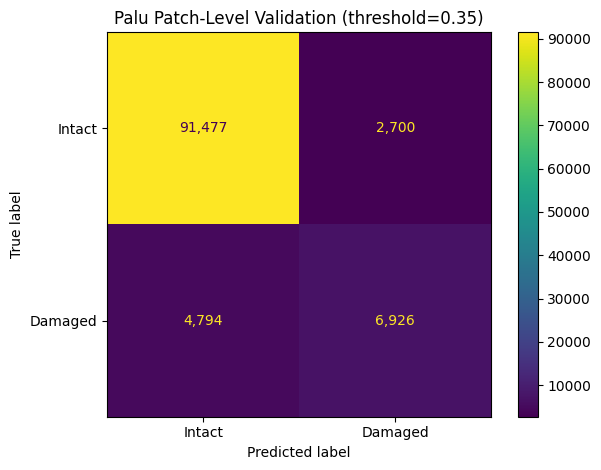

,threshold,intact_precision,intact_recall,intact_f1,damaged_precision,damaged_recall,damaged_f1,accuracy,macro_f1,weighted_f1,balanced_accuracy,average_precision,roc_auc
0,0.35,0.9502,0.9713,0.9607,0.7195,0.591,0.6489,0.9292,0.8048,0.9262,0.7811,0.7066,0.8958


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score
)

# Predict on held-out validation patches.
y_val_prob = rf_validation.predict_proba(X_val)[:, 1]
y_val_pred = (y_val_prob >= THRESHOLD).astype(np.uint8)

# Full classification report.
report = classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1],
    target_names=["Intact", "Damaged"],
    digits=4,
    zero_division=0,
    output_dict=True
)

print("=" * 65)
print("FINAL RANDOM FOREST — PALU PATCH-LEVEL VALIDATION")
print("=" * 65)
print(f"Classification threshold: {THRESHOLD:.2f}\n")

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1],
        target_names=["Intact", "Damaged"],
        digits=4,
        zero_division=0
    )
)

balanced_acc = balanced_accuracy_score(y_val, y_val_pred)
avg_precision = average_precision_score(y_val, y_val_prob)
roc_auc = roc_auc_score(y_val, y_val_prob)

print(f"Balanced accuracy: {balanced_acc:.4f}")
print(f"Damaged-class average precision: {avg_precision:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

# Confusion matrix.
cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])

print("\nConfusion matrix (rows=true, columns=predicted):")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Intact", "Damaged"]
)
disp.plot(values_format=",")
plt.title(f"Palu Patch-Level Validation (threshold={THRESHOLD:.2f})")
plt.tight_layout()
plt.show()

# Store the validation metrics for later reference.
validation_metrics = {
    "threshold": THRESHOLD,
    "intact_precision": report["Intact"]["precision"],
    "intact_recall": report["Intact"]["recall"],
    "intact_f1": report["Intact"]["f1-score"],
    "damaged_precision": report["Damaged"]["precision"],
    "damaged_recall": report["Damaged"]["recall"],
    "damaged_f1": report["Damaged"]["f1-score"],
    "accuracy": report["accuracy"],
    "macro_f1": report["macro avg"]["f1-score"],
    "weighted_f1": report["weighted avg"]["f1-score"],
    "balanced_accuracy": balanced_acc,
    "average_precision": avg_precision,
    "roc_auc": roc_auc
}

display(pd.DataFrame([validation_metrics]).round(4))

### Checking Feature Importance

,feature,importance
23,S2_change_B12,0.09594
22,S2_change_B11,0.08941
20,S2_change_B4,0.08063
18,S2_change_B2,0.06304
21,S2_change_B8,0.05532
19,S2_change_B3,0.05048
15,S2_post_B12,0.04690
17,S1_change_VH,0.04510
13,S2_post_B8,0.03941
12,S2_post_B4,0.03914


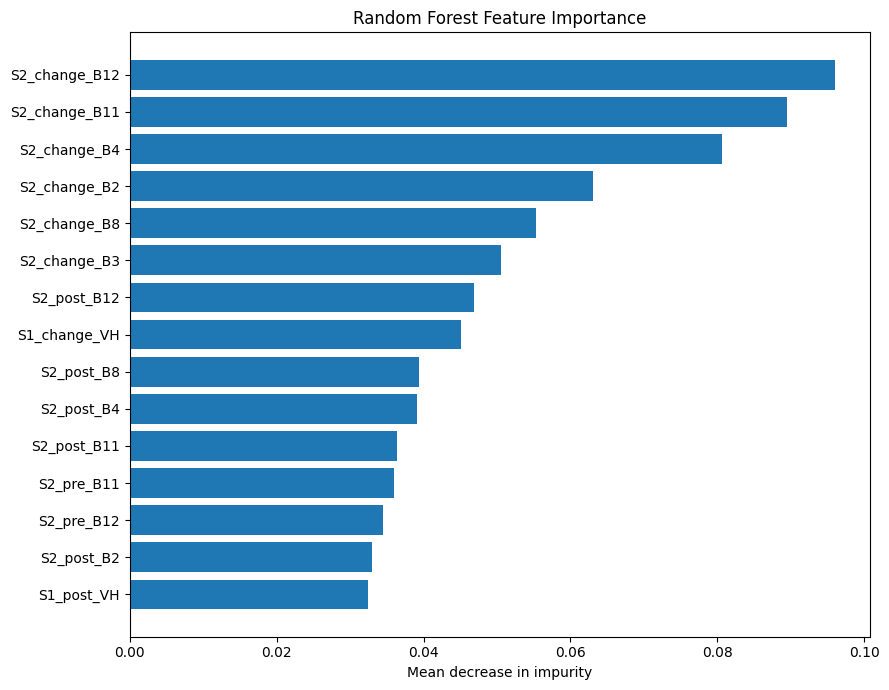

In [13]:
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_validation.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.round(5))

plt.figure(figsize=(9, 7))
top_features = importance_df.head(15).sort_values("importance")

plt.barh(
    top_features["feature"],
    top_features["importance"]
)
plt.xlabel("Mean decrease in impurity")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


## 5. Final Model Fitting and Export

After validation, the selected Random Forest configuration is refitted using all available Palu samples.

The held-out validation metrics remain the performance estimate from the preceding train–validation experiment. Because the exported model is fitted on all Palu samples, these metrics are not an independent evaluation of the exported model.

The model, feature schema, classification threshold, and validation metrics are saved for reproducibility and subsequent inference.

In [14]:
from pathlib import Path
import json
import joblib
import time

OUTPUT_DIR = Path("/content/shoregate_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "shoregate_rf_palu.joblib"
SCHEMA_PATH = OUTPUT_DIR / "shoregate_rf_feature_schema.json"
METRICS_PATH = OUTPUT_DIR / "palu_validation_metrics.json"
IMPORTANCE_PATH = OUTPUT_DIR / "palu_feature_importance.csv"

# Fit the deployment model on all available Palu samples.
rf_final = RandomForestClassifier(**FINAL_PARAMS)

print("Fitting final model on all Palu samples...")

start_time = time.time()
rf_final.fit(X, y)
final_training_minutes = (time.time() - start_time) / 60

print(
    f"Final model fitted in "
    f"{final_training_minutes:.2f} minutes."
)

# Save the fitted model.
joblib.dump(rf_final, MODEL_PATH)

# Save the feature schema and inference settings.
schema = {
    "model_type": "RandomForestClassifier",
    "project": "ShoreGate",
    "training_event": "Palu tsunami",
    "target_classes": {
        "0": "intact",
        "1": "damaged"
    },
    "feature_names": feature_names.tolist(),
    "n_features": int(len(feature_names)),
    "feature_definition": (
        "S1/S2 pre-event, post-event, and post-minus-pre features"
    ),
    "classification_threshold": float(THRESHOLD),
    "model_parameters": {
        "n_estimators": 300,
        "max_features": "sqrt",
        "min_samples_leaf": 1,
        "class_weight": {"0": 1, "1": 3},
        "random_state": 42
    },
    "training_samples": int(len(y)),
    "training_patches": int(len(np.unique(patch_ids))),
    "validation_method": "GroupShuffleSplit by patch_ids",
    "validation_random_state": 42
}

with open(SCHEMA_PATH, "w", encoding="utf-8") as f:
    json.dump(schema, f, indent=2)

# Save validation metrics separately.
with open(METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(
        {
            **validation_metrics,
            "validation_training_minutes": validation_training_minutes,
            "final_training_minutes": final_training_minutes
        },
        f,
        indent=2
    )

# Save feature importance.
importance_df.to_csv(IMPORTANCE_PATH, index=False)

print("\nSaved artifacts:")
print(MODEL_PATH)
print(SCHEMA_PATH)
print(METRICS_PATH)
print(IMPORTANCE_PATH)

Fitting final model on all Palu samples...
Final model fitted in 23.39 minutes.

Saved artifacts:
/content/shoregate_outputs/shoregate_rf_palu.joblib
/content/shoregate_outputs/shoregate_rf_feature_schema.json
/content/shoregate_outputs/palu_validation_metrics.json
/content/shoregate_outputs/palu_feature_importance.csv


In [15]:
loaded_model = joblib.load(MODEL_PATH)

with open(SCHEMA_PATH, "r", encoding="utf-8") as f:
    loaded_schema = json.load(f)

assert loaded_model.n_features_in_ == len(feature_names)
assert loaded_schema["feature_names"] == feature_names.tolist()
assert loaded_schema["classification_threshold"] == THRESHOLD
assert np.array_equal(loaded_model.classes_, np.array([0, 1]))

print("Model and schema verification passed.")
print("Expected feature count:", loaded_model.n_features_in_)
print("Class labels:", loaded_model.classes_)
print("Classification threshold:", loaded_schema["classification_threshold"])
print("Model file size:", f"{MODEL_PATH.stat().st_size / (1024**2):.2f} MiB")

Model and schema verification passed.
Expected feature count: 24
Class labels: [0 1]
Classification threshold: 0.35
Model file size: 1032.11 MiB


In [16]:
from google.colab import files

files.download(str(MODEL_PATH))
files.download(str(SCHEMA_PATH))
files.download(str(METRICS_PATH))
files.download(str(IMPORTANCE_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>